# 04 — Thêm dữ liệu thời tiết cho 8 thành phố (nhiệt độ, độ ẩm, gió, mưa, áp suất)

Notebook này làm **một việc**: lấy thời tiết theo ngày cho cùng 8 thành phố, cùng giai đoạn với dữ liệu CPCB, kiểm tra, rồi ghép vào bảng chính để phần phân tích tương quan và dự đoán dùng.

**Nguồn:** Open-Meteo Historical Weather API, dữ liệu tái phân tích ERA5 (không phải số đo tại trạm). Giấy phép CC BY 4.0, nên báo cáo phải ghi "Weather data by Open-Meteo.com".
**Đầu vào:** `data/processed/air_quality_8cities.csv` (do `01_cleaning` tạo, **không bị sửa**).
**Đầu ra:** `data/processed/air_quality_8cities_weather.csv` (bảng chính + cột thời tiết) và `data/processed/weather_daily_8cities.csv` (thời tiết theo ngày, có thêm vài ngày đầu để sau này tạo biến trễ).
**Dữ liệu tải về:** lưu ở `data/raw/weather/` (theo giờ, không sửa). Lần chạy sau đọc lại từ đó, không gọi API nữa.

**Cách chạy:** *Kernel -> Restart & Run All*, từ thư mục `notebooks/`, máy có mạng. Lần đầu tải 8 thành phố mất vài phút.

**Việc chưa làm ở đây (cố ý):** scale, biến trễ, trung bình trượt. Các bước đó phải làm *sau khi chia train/test theo thời gian*, nếu không sẽ rò rỉ dữ liệu.

## 0. Setup

In [2]:
import sys, os
sys.path.append(os.path.abspath("../src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import weather_utils as wu

pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
print(wu.ATTRIBUTION)

Weather data by Open-Meteo.com (CC BY 4.0), dữ liệu tái phân tích ERA5 (ECMWF / Copernicus)


## 1. Toạ độ và khoảng thời gian

Mỗi thành phố dùng **một điểm** ở trung tâm. Lấy dư từ 25/12/2014 để sau này tạo biến trễ (lag) mà không mất những ngày đầu; bảng chính vẫn bắt đầu 01/01/2015.

In [3]:
coords = pd.DataFrame(wu.CITY_COORDS, index=["lat", "lon"]).T
print(f"Khoảng tải: {wu.START} -> {wu.END}, múi giờ {wu.TIMEZONE}, mô hình {wu.MODEL}")
coords

Khoảng tải: 2014-12-25 -> 2020-07-01, múi giờ Asia/Kolkata, mô hình era5


,lat,lon
Delhi,28.61,77.21
Gurugram,28.46,77.03
Lucknow,26.85,80.95
Jaipur,26.91,75.79
Bengaluru,12.97,77.59
Amritsar,31.63,74.87
Chennai,13.08,80.27
Hyderabad,17.39,78.49


## 2. Thử API trước khi tải thật

Tải thử 7 ngày của Delhi (mong đợi 168 dòng giờ). Nếu báo lỗi về tham số `models`, đặt `wu.MODEL = None` ở ô này rồi chạy lại (khi đó ghi rõ trong báo cáo là dùng mô hình mặc định của API).

Cũng thử xem có lấy được **chiều cao lớp biên khí quyển** không (biến liên quan tới hiện tượng ô nhiễm bị nén sát mặt đất vào mùa đông). Lấy được thì dùng, không thì bỏ qua, các phần sau tự thích ứng.

In [4]:
wu.smoke_test()
USE_BLH = bool(wu.probe_variable("boundary_layer_height"))
print("Có lấy được boundary_layer_height:", USE_BLH)

OK: 168 dòng giờ (mong đợi 168), ô lưới dùng: lat 28.5, lon 77.25, cao 217.0 m
Có lấy được boundary_layer_height: True


## 3. Tải 8 thành phố (theo giờ)

Có bản lưu rồi thì đọc lại. Bị giới hạn tần suất (429) thì code tự chờ và thử lại.

In [5]:
variables = wu.HOURLY_CORE + (wu.HOURLY_EXTRA if USE_BLH else [])
hourly = wu.fetch_all(variables)

Delhi: 48,384 dòng giờ (vừa tải)
Gurugram: 48,384 dòng giờ (vừa tải)
Lucknow: 48,384 dòng giờ (vừa tải)
Jaipur: 48,384 dòng giờ (vừa tải)
Bengaluru: 48,384 dòng giờ (vừa tải)
Amritsar: 48,384 dòng giờ (vừa tải)
Chennai: 48,384 dòng giờ (vừa tải)
Hyderabad: 48,384 dòng giờ (vừa tải)


## 4. Kiểm tra dữ liệu giờ (trước khi gộp)

Với dữ liệu tái phân tích, mong đợi: đủ số giờ (số ngày x 24), không giờ nào trùng, không ô trống. Có chỗ nào lệch thì dừng ở đây, chưa đi tiếp.

Bảng thứ hai là **ô lưới thật** mà API dùng cho từng thành phố. Delhi và Gurugram cách nhau chỉ khoảng 25-30 km nên nhiều khả năng rơi cùng một ô hoặc ô sát nhau: thời tiết của hai thành phố này sẽ gần như giống hệt, cần ghi vào Hạn chế.

In [6]:
rep = pd.DataFrame({c: wu.check_hourly(h, variables) for c, h in hourly.items()}).T
display(rep)

assert (rep["so_dong"] == rep["mong_doi"]).all(), "Có thành phố thiếu hoặc thừa dòng giờ"
assert (rep["gio_trung"] == 0).all(), "Có giờ bị trùng"
assert (rep["o_trong"] == 0).all(), "Có ô trống trong dữ liệu giờ"

grid = pd.DataFrame({c: h[["grid_lat", "grid_lon", "grid_elev"]].iloc[0] for c, h in hourly.items()}).T
grid.insert(0, "lat_yeu_cau", [wu.CITY_COORDS[c][0] for c in grid.index])
grid.insert(1, "lon_yeu_cau", [wu.CITY_COORDS[c][1] for c in grid.index])
same_cell = bool((grid.loc["Delhi", ["grid_lat", "grid_lon"]] == grid.loc["Gurugram", ["grid_lat", "grid_lon"]]).all())
print("Delhi và Gurugram dùng cùng một ô lưới:", same_cell)
grid

,so_dong,mong_doi,gio_trung,o_trong,dau,cuoi
Delhi,48384,48384,0,0,2014-12-25 00:00,2020-07-01 23:00
Gurugram,48384,48384,0,0,2014-12-25 00:00,2020-07-01 23:00
Lucknow,48384,48384,0,0,2014-12-25 00:00,2020-07-01 23:00
Jaipur,48384,48384,0,0,2014-12-25 00:00,2020-07-01 23:00
Bengaluru,48384,48384,0,0,2014-12-25 00:00,2020-07-01 23:00
Amritsar,48384,48384,0,0,2014-12-25 00:00,2020-07-01 23:00
Chennai,48384,48384,0,0,2014-12-25 00:00,2020-07-01 23:00
Hyderabad,48384,48384,0,0,2014-12-25 00:00,2020-07-01 23:00


Delhi và Gurugram dùng cùng một ô lưới: False


,lat_yeu_cau,lon_yeu_cau,grid_lat,grid_lon,grid_elev
Delhi,28.61,77.21,28.50,77.25,217.0
Gurugram,28.46,77.03,28.50,77.00,229.0
Lucknow,26.85,80.95,26.75,81.00,117.0
Jaipur,26.91,75.79,27.00,75.75,430.0
Bengaluru,12.97,77.59,13.00,77.50,914.0
Amritsar,31.63,74.87,31.75,74.75,234.0
Chennai,13.08,80.27,13.00,80.25,10.0
Hyderabad,17.39,78.49,17.50,78.50,502.0


## 5. Gộp theo ngày

Từ 24 giá trị giờ của mỗi ngày (theo múi giờ Ấn Độ) tính ra các cột ngày. Hai điểm cần hiểu:

- **Hướng gió** là góc vòng tròn (359° và 1° gần nhau), nên không đưa số độ vào tương quan hay hồi quy. Thay vào đó tính hai thành phần `wind_u` (Đông-Tây) và `wind_v` (Bắc-Nam) rồi lấy trung bình ngày. Cột chữ `wind_dir_8` chỉ để mô tả.
- **Mưa** lệch phải rất mạnh, phần lớn ngày bằng 0. Giữ nguyên tổng mưa, thêm cờ `rain_day`. **Không coi ngày mưa lớn là outlier để loại**: đó là mưa gió mùa thật.

In [7]:
daily = wu.build_daily(hourly)          # tự assert mỗi ngày đủ 24 giờ
wcols = wu.weather_cols(daily)
print(daily.shape, "| các cột thời tiết:", wcols)
daily.head()

(16128, 16) | các cột thời tiết: ['temp_mean', 'temp_min', 'temp_max', 'humidity_mean', 'pressure_mean', 'wind_speed_mean', 'wind_speed_max', 'wind_u', 'wind_v', 'precip_sum', 'blh_mean', 'blh_min', 'rain_day', 'wind_dir_8']


,City,Date,temp_mean,temp_min,temp_max,humidity_mean,pressure_mean,wind_speed_mean,wind_speed_max,wind_u,wind_v,precip_sum,blh_mean,blh_min,rain_day,wind_dir_8
0,Delhi,2014-12-25,10.63,7.3,16.2,83.33,993.05,2.85,4.04,2.29,-1.54,0.0,302.71,60.0,False,NW
1,Delhi,2014-12-26,11.28,7.4,17.4,77.50,991.65,3.68,5.45,3.15,-1.78,0.0,386.46,125.0,False,NW
2,Delhi,2014-12-27,11.80,7.5,19.7,75.58,991.35,3.14,3.83,1.89,-1.81,0.0,338.96,25.0,False,NW
3,Delhi,2014-12-28,10.88,5.9,18.7,78.25,993.28,1.90,2.73,-0.05,-1.74,0.0,222.71,15.0,False,N
4,Delhi,2014-12-29,11.38,6.6,19.2,75.79,991.66,1.90,2.55,0.19,-1.79,0.0,191.46,20.0,False,N


**Kiểm tra riêng phần hướng gió** (4 hướng cơ bản phải ra đúng nhãn, vì hướng gió là hướng gió thổi *từ* đâu): gió từ Bắc thổi về Nam nên `v < 0`, gió từ Đông thổi về Tây nên `u < 0`.

In [8]:
u = pd.Series([0.0, -1.0, 0.0, 1.0]); v = pd.Series([-1.0, 0.0, 1.0, 0.0])
assert wu._dir8(u, v).tolist() == ["N", "E", "S", "W"], "Nhãn hướng gió bị đảo"
print("Hướng gió: 4 hướng cơ bản đúng")

Hướng gió: 4 hướng cơ bản đúng


## 6. Kiểm tra hợp lý

**6a. Giới hạn vật lý (dừng nếu vi phạm).** Ngoài khoảng này là lỗi dữ liệu hoặc lỗi đơn vị.

In [9]:
viol = wu.check_ranges(daily)
print(f"{len(viol)} ô vi phạm giới hạn vật lý")
display(viol.head(10))
assert viol.empty, "Có giá trị ngoài giới hạn vật lý, xem bảng trên"

0 ô vi phạm giới hạn vật lý


,City,Date,gia_tri,vi_pham


**6b. Đối chiếu với khí hậu đã biết (chỉ cảnh báo, không dừng).** Ví dụ Amritsar mùa đông lạnh, Chennai nóng quanh năm, vùng gió mùa hè có mưa dồn vào tháng 6-9. Ngưỡng là ước lượng thô nên chỉ để mắt thường xem lại.

In [10]:
warns = wu.soft_checks(daily)
print("Không có cảnh báo" if not warns else "\n".join("CẢNH BÁO: " + w for w in warns))
summary = wu.city_summary(daily)
summary

Không có cảnh báo


,so_ngay,nhiet_do_tb,do_am_tb,gio_tb_m/s,mua_mm_moi_nam,ty_le_ngay_mua
City,,,,,,
Delhi,2016,24.9,66.0,2.5,706.0,0.24
Gurugram,2016,25.1,64.0,2.4,663.0,0.23
Lucknow,2016,25.5,67.0,2.6,1077.0,0.26
Jaipur,2016,25.3,55.0,2.6,547.0,0.18
Bengaluru,2016,24.1,69.0,3.0,923.0,0.35
Amritsar,2016,23.7,68.0,2.0,675.0,0.26
Chennai,2016,28.5,76.0,3.6,970.0,0.29
Hyderabad,2016,27.1,62.0,3.0,844.0,0.25


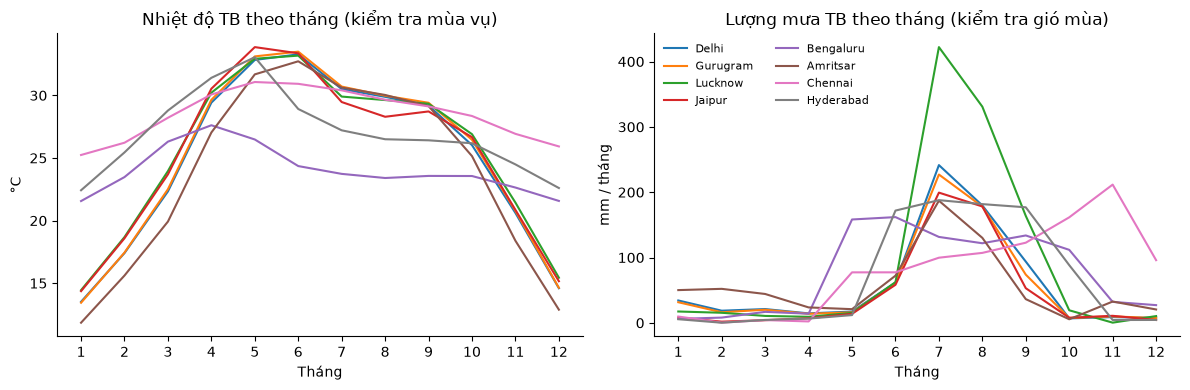

In [11]:
d = daily.assign(month=daily["Date"].dt.month)
temp_m = d.groupby(["month", "City"])["temp_mean"].mean().unstack()[wu.CITIES]
rain_m = (d.assign(year=d["Date"].dt.year).query("2016 <= year <= 2019")
           .groupby(["month", "City"])["precip_sum"].sum().div(4).unstack()[wu.CITIES])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
temp_m.plot(ax=axes[0], legend=False); axes[0].set_title("Nhiệt độ TB theo tháng (kiểm tra mùa vụ)"); axes[0].set_ylabel("°C")
rain_m.plot(ax=axes[1]); axes[1].set_title("Lượng mưa TB theo tháng (kiểm tra gió mùa)"); axes[1].set_ylabel("mm / tháng")
axes[1].legend(fontsize=8, ncol=2, frameon=False)
for ax in axes: ax.set_xlabel("Tháng"); ax.set_xticks(range(1, 13)); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 7. Ghép vào bảng chính

Ghép trái theo (`City`, `Date`). Điều kiện kiểm tra: số dòng **không đổi**, không dòng nào thiếu thời tiết, và các cột cũ **giống hệt** bản gốc.

In [12]:
aq = pd.read_csv(wu.AQ_FILE, parse_dates=["Date"])
merged = wu.merge_weather(aq, daily)

assert len(merged) == len(aq), f"Số dòng đổi: {len(aq)} -> {len(merged)}"
assert not merged.duplicated(wu.KEYS).any(), "Có khoá (City, Date) trùng"
n_missing_weather = int(merged[wcols].isna().any(axis=1).sum())
assert n_missing_weather == 0, f"{n_missing_weather} dòng không có thời tiết"
pd.testing.assert_frame_equal(merged[aq.columns], aq)     # cột cũ không bị đụng tới

print(f"OK: {len(aq):,} dòng giữ nguyên, {len(aq.columns)} cột cũ giữ nguyên, thêm {len(wcols)} cột thời tiết -> {merged.shape[1]} cột")
merged[["City", "Date", "AQI", "PM2.5"] + wcols].head()

OK: 14,056 dòng giữ nguyên, 40 cột cũ giữ nguyên, thêm 14 cột thời tiết -> 54 cột


,City,Date,AQI,PM2.5,temp_mean,temp_min,temp_max,humidity_mean,pressure_mean,wind_speed_mean,wind_speed_max,wind_u,wind_v,precip_sum,blh_mean,blh_min,rain_day,wind_dir_8
0,Delhi,2015-01-01,472.0,313.22,15.55,11.4,20.9,72.75,991.19,1.84,2.47,-1.08,-0.48,0.0,180.21,30.0,False,NE
1,Delhi,2015-01-02,454.0,186.18,15.10,13.5,15.9,87.79,992.18,1.94,3.10,-1.68,-0.53,4.2,241.46,20.0,True,E
2,Delhi,2015-01-03,143.0,87.18,15.42,14.6,16.6,91.25,991.65,1.42,2.51,0.87,-0.78,0.1,203.96,20.0,False,NW
3,Delhi,2015-01-04,319.0,151.84,14.19,11.5,18.1,84.62,993.31,2.83,3.74,1.90,-2.04,0.0,404.38,70.0,False,NW
4,Delhi,2015-01-05,325.0,146.60,13.98,9.8,20.4,77.75,990.41,5.19,7.50,4.40,-2.72,0.0,480.62,160.0,False,NW


## 8. Lưu

In [13]:
merged.to_csv(wu.OUT_MERGED, index=False)
daily.to_csv(wu.OUT_DAILY, index=False)
print("Đã lưu:", wu.OUT_MERGED.relative_to(wu.ROOT), "|", wu.OUT_DAILY.relative_to(wu.ROOT))

Đã lưu: data\processed\air_quality_8cities_weather.csv | data\processed\weather_daily_8cities.csv


## 9. Dòng nhật ký để dán vào `reports/cleaning_log_8cities.md`

Nhóm chỉ giữ **một** nhật ký làm sạch duy nhất, nên **không** tạo file nhật ký mới. Ô dưới in sẵn các dòng (số liệu lấy từ lần chạy này) theo đúng cột của bảng nhật ký (STT, Bước, Cột, Phát hiện, Hành động, Ảnh hưởng, Lý do & kiểm chứng). Đọc lại cho đúng rồi dán vào cuối bảng ở mục 2; chỉnh STT cho khớp (hiện đang xếp sau bước 11).

In [14]:
n_city = len(hourly); n_hours = int(rep["so_dong"].sum()); n_days = len(daily)
n_blh = " (có thêm `blh_mean`, `blh_min`)" if USE_BLH else ""
rain_days = daily["rain_day"].mean()
max_rain = daily.loc[daily["precip_sum"].idxmax()]
skew = daily["precip_sum"].skew()
f = lambda x: f"{x:,}".replace(",", ".")          # 14056 -> 14.056 (như bảng nhật ký hiện có)

rows = [
 f"| 12 | Thêm dữ liệu thời tiết (nguồn thứ hai) | {len(wcols)} cột thời tiết | Dữ liệu CPCB không có biến khí tượng. Lấy từ Open-Meteo (ERA5), {n_city} thành phố, theo giờ, {wu.START} đến {wu.END} | Tải theo toạ độ trung tâm từng thành phố, lưu bản gốc ở `data/raw/weather/`, không sửa | {f(n_hours)} dòng giờ | Cần biến giải thích cho phần tương quan và dự đoán. Dữ liệu tái phân tích nên phủ đủ ngày. *Kiểm chứng:* số dòng = số ngày x 24 cho cả {n_city} thành phố, 0 giờ trùng, 0 ô trống |",
 f"| 13 | Chuẩn hoá múi giờ và gộp theo ngày | tất cả cột thời tiết | \"Ngày\" của CPCB theo giờ Ấn Độ (UTC+5:30); để mặc định UTC thì ngày lệch 5,5 giờ | Yêu cầu API trả giờ theo `{wu.TIMEZONE}`, gộp 24 giờ thành 1 ngày (trung bình, min, max, tổng mưa) | {f(n_days)} ngày-thành phố | Ghép sai múi giờ sẽ lệch ngày mà không báo lỗi. *Kiểm chứng:* mỗi ngày đủ đúng 24 giờ |",
 f"| 14 | Biến hướng gió thành 2 thành phần | wind_u, wind_v (và wind_dir_8 để mô tả) | Hướng gió là góc vòng tròn (359° ≈ 1°) | Tính thành phần Đông (`wind_u`) và Bắc (`wind_v`) từ tốc độ và hướng, lấy trung bình ngày; chỉ giữ số độ ở dạng chữ 8 hướng để mô tả | {f(n_days)} ngày-thành phố | Tương quan và hồi quy trên số độ thô sẽ sai ở chỗ 0°/360°. *Kiểm chứng:* thử riêng 4 hướng Bắc, Đông, Nam, Tây ra đúng nhãn |",
 f"| 15 | Giữ nguyên mưa lớn, không coi là outlier | precip_sum, rain_day | Mưa lệch phải (skew = {str(round(skew, 1)).replace(".", ",")}): chỉ {rain_days:.0%} số ngày có mưa từ {wu.RAIN_DAY_MM:g} mm; ngày mưa nhất là {max_rain['City']} {max_rain['Date']:%d/%m/%Y} với {max_rain['precip_sum']:.0f} mm | Không loại, không cắt; thêm cờ `rain_day` | 0 ô sửa | Đây là mưa gió mùa thật, loại đi là mất đúng tín hiệu cần phân tích. Biến đổi (vd `log1p`) để dành lúc dựng mô hình. *Kiểm chứng:* mọi giá trị nằm trong giới hạn vật lý (mưa ngày ≤ 500 mm) |",
 f"| 16 | Kiểm tra hợp lý với khí hậu | nhiệt độ, mưa | So khí hậu từng thành phố với kiến thức nền (Amritsar lạnh vào tháng 1, Chennai nóng quanh năm, mưa vùng gió mùa hè dồn vào tháng 6-9): {len(warns)} cảnh báo | " + ("Không xử lý" if not warns else "Xem lại các cảnh báo") + f" | 0 ô sửa | Không có nguồn đo tại trạm để đối chiếu, nên chỉ kiểm bằng kiến thức khí hậu. *Kiểm chứng:* bảng tóm tắt và biểu đồ theo tháng ở mục 6 |",
 f"| 17 | Ghép vào bảng chính | {len(wcols)} cột mới | Ghép trái theo (City, Date) | Xuất file mới `air_quality_8cities_weather.csv`, không sửa `air_quality_8cities.csv` | {f(len(merged))} dòng giữ nguyên, 0 dòng thiếu thời tiết | Giữ nguyên bảng cũ để phần EDA đã làm không bị ảnh hưởng. *Kiểm chứng:* số dòng không đổi, các cột cũ giống hệt bản gốc (`assert_frame_equal`) |",
]
print("\n".join(rows))

| 12 | Thêm dữ liệu thời tiết (nguồn thứ hai) | 14 cột thời tiết | Dữ liệu CPCB không có biến khí tượng. Lấy từ Open-Meteo (ERA5), 8 thành phố, theo giờ, 2014-12-25 đến 2020-07-01 | Tải theo toạ độ trung tâm từng thành phố, lưu bản gốc ở `data/raw/weather/`, không sửa | 387.072 dòng giờ | Cần biến giải thích cho phần tương quan và dự đoán. Dữ liệu tái phân tích nên phủ đủ ngày. *Kiểm chứng:* số dòng = số ngày x 24 cho cả 8 thành phố, 0 giờ trùng, 0 ô trống |
| 13 | Chuẩn hoá múi giờ và gộp theo ngày | tất cả cột thời tiết | "Ngày" của CPCB theo giờ Ấn Độ (UTC+5:30); để mặc định UTC thì ngày lệch 5,5 giờ | Yêu cầu API trả giờ theo `Asia/Kolkata`, gộp 24 giờ thành 1 ngày (trung bình, min, max, tổng mưa) | 16.128 ngày-thành phố | Ghép sai múi giờ sẽ lệch ngày mà không báo lỗi. *Kiểm chứng:* mỗi ngày đủ đúng 24 giờ |
| 14 | Biến hướng gió thành 2 thành phần | wind_u, wind_v (và wind_dir_8 để mô tả) | Hướng gió là góc vòng tròn (359° ≈ 1°) | Tính thành phần Đông (`wind_u`) và Bắc (`wind_v`)

## 10. Đoạn bổ sung cho `Data_dictionary.md` (mục 2) và mục Hạn chế

**Từ điển các cột thời tiết** (dán vào `Data_dictionary.md`, kèm dòng nguồn và ghi công):

In [15]:
print("**Nguồn thời tiết:** Open-Meteo Historical Weather API (dữ liệu tái phân tích ERA5), tải theo giờ cho toạ độ trung tâm từng thành phố, múi giờ Asia/Kolkata, gộp theo ngày. " + wu.ATTRIBUTION + ".\n")
print(wu.dictionary_markdown(USE_BLH))

**Nguồn thời tiết:** Open-Meteo Historical Weather API (dữ liệu tái phân tích ERA5), tải theo giờ cho toạ độ trung tâm từng thành phố, múi giờ Asia/Kolkata, gộp theo ngày. Weather data by Open-Meteo.com (CC BY 4.0), dữ liệu tái phân tích ERA5 (ECMWF / Copernicus).

| Cột | Kiểu | Đơn vị | Ý nghĩa | Cách tính |
|---|---|---|---|---|
| `temp_mean` | float | °C | Nhiệt độ không khí ở độ cao 2 m, trung bình ngày | mean của 24 giá trị giờ |
| `temp_min` | float | °C | Nhiệt độ thấp nhất trong ngày | min của 24 giá trị giờ |
| `temp_max` | float | °C | Nhiệt độ cao nhất trong ngày | max của 24 giá trị giờ |
| `humidity_mean` | float | % | Độ ẩm tương đối ở 2 m, trung bình ngày | mean của 24 giá trị giờ |
| `pressure_mean` | float | hPa | Áp suất bề mặt, trung bình ngày (phụ thuộc độ cao: Bengaluru thấp hơn các thành phố khác) | mean của 24 giá trị giờ |
| `wind_speed_mean` | float | m/s | Tốc độ gió ở 10 m, trung bình ngày | mean của 24 giá trị giờ |
| `wind_speed_max` | float | m/s | Tốc độ

**Gợi ý nội dung mục Hạn chế** (sửa cho khớp kết quả thật ở mục 4 trước khi dán):

- Thời tiết là dữ liệu **mô hình** (tái phân tích ERA5), không phải số đo tại trạm; giá trị là trung bình trên một ô lưới quanh một điểm, còn AQI của CPCB là trung bình các trạm trong thành phố, nên hai thứ không khớp hoàn toàn về không gian.
- Mỗi thành phố chỉ dùng **một điểm toạ độ**.
- Delhi và Gurugram rất gần nhau nên thời tiết gần như trùng nhau (xem bảng ô lưới ở mục 4); không nên coi hai thành phố là hai quan sát thời tiết độc lập.
- Quan hệ thời tiết - AQI chỉ nói "có liên quan", không nói "gây ra": nhiệt độ, gió và mùa đi cùng nhau, và các nguồn phát thải (đốt rơm rạ, giao thông, sưởi) cũng thay đổi theo mùa mà dữ liệu này không có.